In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.metrics.pairwise import rbf_kernel

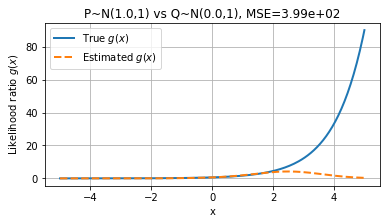

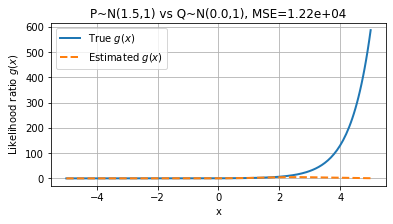

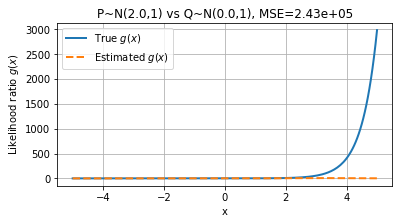

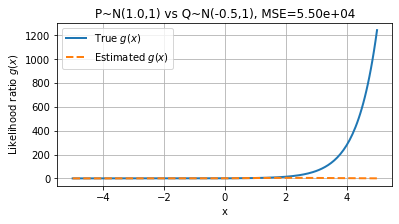

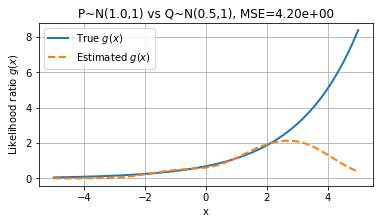

Summary of MSEs:
P~N(1.0,1) vs Q~N(0.0,1): MSE = 3.99e+02
P~N(1.5,1) vs Q~N(0.0,1): MSE = 1.22e+04
P~N(2.0,1) vs Q~N(0.0,1): MSE = 2.43e+05
P~N(1.0,1) vs Q~N(-0.5,1): MSE = 5.50e+04
P~N(1.0,1) vs Q~N(0.5,1): MSE = 4.20e+00


In [7]:
class LikelihoodRatioEstimator:
    """
    Estimate the likelihood ratio g(x) = p(x) / q(x)
    from samples X_p ~ P and X_q ~ Q using a Gaussian RBF kernel
    and Tikhonov regularization in RKHS.
    """
    def __init__(self, sigma=1.0, lambda_reg=1e-2):
        """
        Parameters:
        - sigma: bandwidth for the Gaussian RBF kernel.
        - lambda_reg: regularization strength.
        """
        self.sigma = sigma
        self.lambda_reg = lambda_reg
        self.alpha = None
        self.X_p = None
        self.n_p = None

    def _build_kernel(self, X_p, X_q):
        """
        Build kernel Gram matrices:
          K_pp: (n_p x n_p) between P samples
          K_qp: (n_q x n_p) between Q and P samples
        """
        self.X_p = X_p
        self.n_p = X_p.shape[0]
        gamma = 1.0 / (2 * self.sigma**2)
        K_pp = rbf_kernel(X_p, X_p, gamma=gamma)
        K_qp = rbf_kernel(X_q, X_p, gamma=gamma)
        return K_pp, K_qp

    def _loss_and_grad(self, alpha, K_pp, K_qp):
        """
        Compute both the loss and its gradient wrt alpha:
          loss = mean(g_q) - mean(log g_p) + (λ/2) α^T K_pp α
        """
        # g evaluated on Q and P samples
        g_q = K_qp @ alpha      # shape (n_q,)
        g_p = K_pp @ alpha      # shape (n_p,)
        # Ensure positivity for log
        g_p = np.clip(g_p, 1e-8, None)

        # Loss components
        fit_q = np.mean(g_q)                           # E_{Q_n}[g]
        fit_p = -np.mean(np.log(g_p))                  # -E_{P_n}[log g]
        reg   = (self.lambda_reg / 2) * (alpha @ (K_pp @ alpha))
        loss = fit_q + fit_p + reg

        # Gradient
        # d/dα mean(g_q) = mean(K_qp, axis=0)
        grad_fit_q = np.mean(K_qp, axis=0)
        # d/dα [-mean(log g_p)] = - (1/n_p) * K_pp^T @ (1/g_p)
        grad_fit_p = -(K_pp @ (1.0 / g_p)) / self.n_p
        # d/dα [ (λ/2) α^T K_pp α ] = λ * K_pp @ α
        grad_reg   = self.lambda_reg * (K_pp @ alpha)

        grad = grad_fit_q + grad_fit_p + grad_reg
        return loss, grad

    def fit(self, X_p, X_q):
        """
        Fit the estimator to samples from P (X_p) and Q (X_q).
        Solves for alpha in the kernel expansion.
        """
        K_pp, K_qp = self._build_kernel(X_p, X_q)

        # Initial alpha: uniform positive
        alpha0 = np.ones(self.n_p) / self.n_p
        bounds = [(0, None)] * self.n_p

        result = minimize(
            fun=lambda a: self._loss_and_grad(a, K_pp, K_qp),
            x0=alpha0,
            method='L-BFGS-B',
            jac=True,
            bounds=bounds,
            options={'maxiter': 1000, 'ftol': 1e-9}
        )
        if not result.success:
            msg = result.message.decode() if isinstance(result.message, bytes) else result.message
            raise RuntimeError("Optimization failed: " + msg)

        self.alpha = result.x

    def predict(self, X):
        """
        Predict g(x) for new data points X, returning an array of length len(X).
        """
        if self.alpha is None:
            raise ValueError("Estimator has not been fitted yet.")
        gamma = 1.0 / (2 * self.sigma**2)
        K_xp = rbf_kernel(X, self.X_p, gamma=gamma)
        return K_xp @ self.alpha

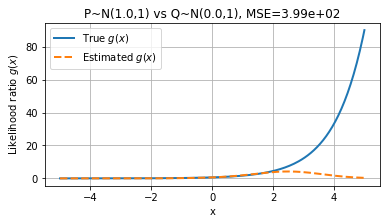

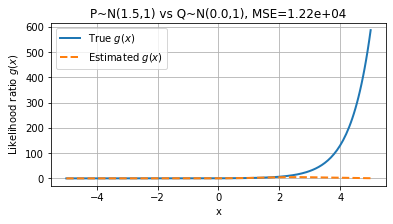

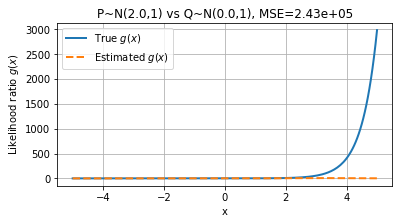

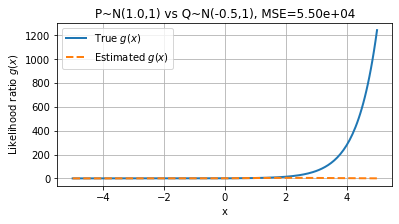

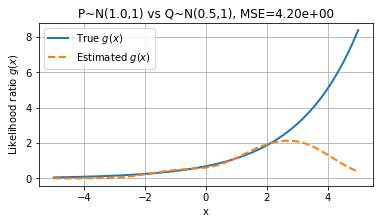

Summary of MSEs:
P~N(1.0,1) vs Q~N(0.0,1): MSE = 3.99e+02
P~N(1.5,1) vs Q~N(0.0,1): MSE = 1.22e+04
P~N(2.0,1) vs Q~N(0.0,1): MSE = 2.43e+05
P~N(1.0,1) vs Q~N(-0.5,1): MSE = 5.50e+04
P~N(1.0,1) vs Q~N(0.5,1): MSE = 4.20e+00


In [9]:
if __name__ == "__main__":
    # -----------------------------
    # Test harness: multiple experiments
    # -----------------------------
    np.random.seed(0)
    experiment_params = [
        (1.0, 0.0),
        (1.5, 0.0),
        (2.0, 0.0),
        (1.0, -0.5),
        (1.0, 0.5)
    ]

    n_train = 200
    n_tests = 200
    X_grid = np.linspace(-5, 5, n_tests).reshape(-1, 1)

    results = []
    for mu_p, mu_q in experiment_params:
        # Generate training samples
        X_p = np.random.normal(mu_p, 1.0, size=(n_train, 1))
        X_q = np.random.normal(mu_q, 1.0, size=(n_train, 1))

        # Fit the likelihood ratio estimator
        lr_est = LikelihoodRatioEstimator(sigma=1.0, lambda_reg=1e-2)
        lr_est.fit(X_p, X_q)

        # Predictions on the grid
        g_hat = lr_est.predict(X_grid).flatten()

        # True likelihood ratio for N(mu_p,1) vs N(mu_q,1):
        # exp((mu_p - mu_q)*x + (mu_q^2 - mu_p^2)/2)
        g_true = np.exp((2*(mu_p - mu_q)*X_grid.flatten() + (mu_q**2 - mu_p**2)) / 2)

        # Compute mean squared error
        mse = np.mean((g_hat - g_true)**2)
        results.append((mu_p, mu_q, mse))

        # Plot result
        plt.figure(figsize=(6, 3))
        plt.plot(X_grid, g_true, label='True $g(x)$', linewidth=2)
        plt.plot(X_grid, g_hat, '--', label='Estimated $g(x)$', linewidth=2)
        plt.title(f"P~N({mu_p},1) vs Q~N({mu_q},1), MSE={mse:.2e}")
        plt.xlabel('x')
        plt.ylabel('Likelihood ratio $g(x)$')
        plt.legend()
        plt.grid(True)
        plt.show()

    # Print summary
    print("Summary of MSEs:")
    for mu_p, mu_q, mse in results:
        print(f"P~N({mu_p},1) vs Q~N({mu_q},1): MSE = {mse:.2e}")